# Power Outages in Ukraine: Data Cleaning and EDA

**Research question:** which factors determine when nationwide planned power outages for households are applied in Ukraine?

Notebook 1 of 2. Four data sources are cleaned and merged into a single hourly table, followed by exploratory data analysis.

**Data sources:**
1. Energy Map, DiXi Group: hourly records of NPC Ukrenergo on the application of electricity consumption restriction measures, 01.01.2023–30.06.2026.
2. Energy Map, DiXi Group: hourly electricity import and export, 07.2019–06.2026.
3. Open-Meteo Historical Weather API: hourly weather for Kyiv, 01.01.2023–30.06.2026.
4. Energy Map, DiXi Group: massive strikes on Ukraine's critical infrastructure according to the Ministry of Energy, Ukrenergo and the Air Force, 09.2022–06.2026.

Download instructions for all files are in `data/README.md`.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap

DATA_DIR = Path("../data/raw")      # raw CSV files, see data/README.md
OUT_DIR = Path("../data/clean")     # cleaned dataset
FIG_DIR = Path("../figures")        # figures
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

OUTAGES_FILE = DATA_DIR / "2026_07_01_electricity_outages.csv"
TRADE_FILE = DATA_DIR / "2026_07_01_import_eksport_pohodynno.csv"
WEATHER_FILE = DATA_DIR / "open-meteo-50.44N30.48E169m.csv"
STRIKES_FILE = DATA_DIR / "2026_07_01_udary_krytychna_infrastruktura.csv"

# Period covered by all hourly sources
START, END = "2023-01-01", "2026-06-30 23:00"

# Period when outage hours were aggregated from distribution system operators
# and do not show the real hourly profile (note by Energy Map)
AGG_START, AGG_END = "2025-12-10", "2026-01-28 23:00"

In [2]:
# Common chart style
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e4e3df"
SEQ = LinearSegmentedColormap.from_list(
    "blue_seq", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.family": "DejaVu Sans", "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

## 1. Power outages

A first look at the file revealed three problems:
- 328 rows from 1 to 14 April 2026 contain Excel formulas such as `=B28442` instead of the date and hour; the row order is preserved, so the timestamps can be restored;
- on the last Sunday of October the hour 03:00–04:00 appears twice because of the switch to winter time;
- from 10.12.2025 to 28.01.2026 outages are marked in every hour because the data were aggregated from distribution system operators.

The source file is in Ukrainian: the value `так` means "yes", i.e. outages were applied in that hour.

In [3]:
out = pd.read_csv(OUTAGES_FILE)
out.columns = ["date", "hour", "outage_raw", "queues_raw", "regions"]
print(out.shape)
out.head()

(30647, 5)


,date,hour,outage_raw,queues_raw,regions
0,2023-01-01,00:00-01:00,ні,NaN,NaN
1,2023-01-01,01:00-02:00,ні,NaN,NaN
2,2023-01-01,02:00-03:00,ні,NaN,NaN
3,2023-01-01,03:00-04:00,ні,NaN,NaN
4,2023-01-01,04:00-05:00,ні,NaN,NaN


In [4]:
# Start of the hour for valid rows
valid = out["date"].notna()
out["dt"] = pd.to_datetime(out.loc[valid, "date"] + " " + out.loc[valid, "hour"].str[:5])

# Restore timestamps in the broken block: last valid timestamp + 1 hour per row
block = out["dt"].notna().cumsum()
out["dt"] = (out.groupby(block)["dt"].transform("first")
             + pd.to_timedelta(out.groupby(block).cumcount(), unit="h"))

broken = out.loc[~valid, "dt"]
print("Restored rows:", len(broken), "|", broken.min(), "to", broken.max())
print("Next valid row:", out.loc[broken.index.max() + 1, "dt"])

Restored rows: 328 | 2026-04-01 00:00:00 to 2026-04-14 15:00:00
Next valid row: 2026-04-14 16:00:00


In [5]:
# Duplicated hour at the switch to winter time: values are identical, keep one row
dups = out[out.duplicated("dt", keep=False)]
print("Duplicated hours:", sorted(dups["dt"].astype(str).unique()))
print("Do duplicate values differ:", dups.groupby("dt")["outage_raw"].nunique().gt(1).any())
out = out.drop_duplicates("dt").reset_index(drop=True)

Duplicated hours: ['2023-10-29 03:00:00', '2024-10-27 03:00:00', '2025-10-26 03:00:00']
Do duplicate values differ: False


In [6]:
def max_queues(x):
    """'від 0,5 до 3' ("from 0.5 to 3") -> 3.0, '2' -> 2.0, empty -> NaN."""
    if pd.isna(x):
        return np.nan
    nums = [float(n.replace(",", ".")) for n in re.findall(r"\d+(?:,\d+)?", str(x))]
    return max(nums) if nums else np.nan

out["outage"] = (out["outage_raw"] == "так").astype(int)   # "так" = "yes"
out["queues_max"] = out["queues_raw"].apply(max_queues)
out.loc[out["outage"] == 0, "queues_max"] = 0.0   # no outages = 0 queues
out["aggregated_period"] = out["dt"].between(AGG_START, AGG_END).astype(int)

outages = out[["dt", "outage", "queues_max", "regions", "aggregated_period"]]
print(outages["outage"].value_counts())
print("\nOutage hours without queue information:", outages["queues_max"].isna().sum())
print("Last date with queue information:", outages.loc[outages["queues_max"] > 0, "dt"].max())
outages.describe(include="all").T

outage
0    24524
1     6120
Name: count, dtype: int64

Outage hours without queue information: 3831
Last date with queue information: 2026-06-30 21:00:00


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
dt,30644,NaN,NaN,NaN,2024-09-30 11:30:35.008484352,2023-01-01 00:00:00,2023-11-16 05:45:00,2024-09-30 11:30:00,2025-08-15 17:15:00,2026-06-30 23:00:00,NaN
outage,30644.0,NaN,NaN,NaN,0.199713,0.0,0.0,0.0,0.0,1.0,0.399791
queues_max,26813.0,NaN,NaN,NaN,0.216667,0.0,0.0,0.0,0.0,5.0,0.771722
regions,6120,5,у більшості областей або в усіх областях,2849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aggregated_period,30644.0,NaN,NaN,NaN,0.039159,0.0,0.0,0.0,0.0,1.0,0.193977


## 2. Weather

The Open-Meteo CSV starts with three lines of metadata that have to be skipped. There are no missing values.

The metadata row contains `utc_offset_seconds = 7200`: the API returned the whole series with a fixed UTC+2 offset, without summer time. The outage and trade files use Kyiv wall-clock time, which is UTC+3 from late March to late October. Without a correction the weather would be shifted by one hour in about half of all hours, so the timestamps are converted to Kyiv time. After the conversion the weather series has the same structure as the outage file: no 03:00 hour on the day of the switch to summer time, and one label for the two hours at the switch to winter time, whose values are averaged.

In [7]:
meta = pd.read_csv(WEATHER_FILE, nrows=1)
utc_offset = pd.Timedelta(seconds=int(meta["utc_offset_seconds"].iloc[0]))
print("Offset of the weather timestamps from UTC:", utc_offset)

weather = pd.read_csv(WEATHER_FILE, skiprows=3)
weather.columns = ["dt", "temp_c", "cloud_pct", "radiation_wm2", "wind_kmh"]

def to_kyiv_time(utc_naive):
    # UTC timestamps -> Kyiv wall-clock time. The zone was renamed in the tz database in 2022,
    # so both names are tried.
    for tz_name in ("Europe/Kyiv", "Europe/Kiev"):
        try:
            return utc_naive.dt.tz_localize("UTC").dt.tz_convert(tz_name).dt.tz_localize(None)
        except Exception:
            continue
    raise RuntimeError("Kyiv time zone not found; install the tzdata package")

weather["dt"] = to_kyiv_time(pd.to_datetime(weather["dt"]) - utc_offset)
print("Duplicated labels at the switch to winter time:", weather["dt"].duplicated().sum())
weather = weather.groupby("dt", as_index=False).mean()
print(weather.shape, "| missing values:", weather.isna().sum().sum())
weather.describe().round(1).T

Offset of the weather timestamps from UTC: 0 days 02:00:00


Duplicated labels at the switch to winter time: 3
(30645, 5) | missing values: 0


,count,mean,min,25%,50%,75%,max,std
dt,30645,2024-09-30 12:00:35.242290688,2023-01-01 00:00:00,2023-11-16 06:00:00,2024-09-30 12:00:00,2025-08-15 18:00:00,2026-07-01 00:00:00,NaN
temp_c,30645.0,10.0,-21.6,2.0,9.8,18.3,35.9,10.1
cloud_pct,30645.0,64.8,0.0,16.0,96.0,100.0,100.0,41.9
radiation_wm2,30645.0,145.7,0.0,0.0,7.0,225.0,911.0,222.7
wind_kmh,30645.0,11.7,0.0,7.8,10.9,14.7,47.1,5.4


## 3. Import and export

The file has separate rows for each country, trading zone and customs regime. The analysis needs one value per hour: total import, total export and net import as their difference. Positive net import means that the power system lacks its own generation.

In [8]:
trade_raw = pd.read_csv(TRADE_FILE)
trade_raw.columns = ["date", "hour", "zone", "country", "regime", "mwh"]
print(trade_raw.shape, "| missing values:", trade_raw.isna().sum().sum())
print(trade_raw["regime"].value_counts().to_dict())
print(sorted(trade_raw["country"].unique()))

trade_raw["dt"] = pd.to_datetime(trade_raw["date"] + " " + trade_raw["hour"].str[:5])
# Note: the two hours at the switch to winter time share one label, so they are summed here
trade = (trade_raw.pivot_table(index="dt", columns="regime", values="mwh", aggfunc="sum")
         .rename(columns={"імпорт": "import_mwh", "експорт": "export_mwh"})   # Ukrainian labels in the source
         .fillna(0).reset_index())
trade["net_import_mwh"] = trade["import_mwh"] - trade["export_mwh"]
trade.tail()

(753365, 6) | missing values: 0
{'експорт': 376761, 'імпорт': 376604}
['Білорусь', 'Білорусь-0.4-110', 'Молдова', 'Польща', 'Російська Федерація', 'Румунія', 'Словаччина', 'Угорщина']


regime,dt,export_mwh,import_mwh,net_import_mwh
61361,2026-06-30 19:00:00,0.0,227.0,227.0
61362,2026-06-30 20:00:00,0.0,204.0,204.0
61363,2026-06-30 21:00:00,0.0,200.0,200.0
61364,2026-06-30 22:00:00,0.0,190.0,190.0
61365,2026-06-30 23:00:00,158.0,97.0,-61.0


## 4. Massive strikes on energy infrastructure

The dataset contains only massive attacks that were officially described as such by the Ministry of Energy or Ukrenergo. Each row corresponds to one weapon type in one attack: the number of missiles or drones fired and shot down. Daily local strikes on frontline regions are not included.

Attacks usually happen at night, while their consequences for the power system last for weeks. Therefore, for each day we compute features that describe the recent history of attacks:
- `attack_day`: whether there was an attack on this day;
- `days_since_attack`: days since the last attack;
- `attacks_7d`, `attacks_30d`: number of attacks in the last 7 and 30 days, including the current day;
- `fired_30d`: number of missiles and drones fired in 30 days;
- `not_down_30d`: how many of them were not shot down, an approximate estimate of hits.

The data start in September 2022, so the 30-day history is already known at the beginning of 2023.

In [9]:
strikes = pd.read_csv(STRIKES_FILE)
strikes["date"] = pd.to_datetime(strikes["date"])
print(strikes.shape)
print(strikes["weapon_type"].value_counts().to_dict())
print("Rows without the number shot down:", strikes["weapon_shot_down"].isna().sum())

# Totals per attack. If the number shot down is unknown, it is set to 0,
# so not_down is an upper-bound estimate
attacks = (strikes.assign(not_down=strikes["weapon_fired"] - strikes["weapon_shot_down"].fillna(0))
           .groupby("date").agg(fired=("weapon_fired", "sum"),
                                shot_down=("weapon_shot_down", "sum"),
                                not_down=("not_down", "sum")))
attacks["attack_day"] = 1
print("Massive attacks by year:")
print(attacks.groupby(attacks.index.year).agg(attacks=("fired", "size"), weapons_fired=("fired", "sum")))

(252, 8)
{'ракета': 184, 'БПЛА': 68}
Rows without the number shot down: 30
Massive attacks by year:
      attacks  weapons_fired
date                        
2022       11            733
2023        5            373
2024       13           1712
2025       24           9115
2026       23          11905


In [10]:
# Daily calendar from the first attack to the end of the period
days = pd.date_range(attacks.index.min(), END[:10], freq="D")
daily = attacks.reindex(days).fillna({"fired": 0, "shot_down": 0, "not_down": 0, "attack_day": 0})
daily.index.name = "day"

daily["attacks_7d"] = daily["attack_day"].rolling(7, min_periods=1).sum()
daily["attacks_30d"] = daily["attack_day"].rolling(30, min_periods=1).sum()
daily["fired_30d"] = daily["fired"].rolling(30, min_periods=1).sum()
daily["not_down_30d"] = daily["not_down"].rolling(30, min_periods=1).sum()

last_attack = pd.Series(daily.index.where(daily["attack_day"] == 1), index=daily.index).ffill()
daily["days_since_attack"] = (daily.index - last_attack).dt.days

strike_feats = daily[["attack_day", "days_since_attack", "attacks_7d", "attacks_30d",
                      "fired_30d", "not_down_30d"]].reset_index()
strike_feats[strike_feats["day"] >= START].describe().round(1).T

,count,mean,min,25%,50%,75%,max,std
day,1277,2024-09-30 00:00:00,2023-01-01 00:00:00,2023-11-16 00:00:00,2024-09-30 00:00:00,2025-08-15 00:00:00,2026-06-30 00:00:00,NaN
attack_day,1277.0,0.1,0.0,0.0,0.0,0.0,1.0,0.2
days_since_attack,1277.0,70.8,0.0,5.0,16.0,98.0,378.0,100.4
attacks_7d,1277.0,0.4,0.0,0.0,0.0,1.0,3.0,0.6
attacks_30d,1277.0,1.6,0.0,0.0,1.0,3.0,7.0,1.8
fired_30d,1277.0,538.0,0.0,0.0,110.0,475.0,3440.0,866.0
not_down_30d,1277.0,77.4,0.0,0.0,35.0,140.0,479.0,99.8


## 5. Merged hourly dataset

The weather series is used as the base because, after the conversion to Kyiv time, it has a complete hourly grid without gaps. Outages and trade are joined by timestamp, and attack features by date.

An attack is assigned to its calendar day, because the register gives no time of day. The attack features of a day are therefore the same for all 24 hours, including the hours before the strike itself.

In [11]:
df = (weather
      .merge(outages, on="dt", how="left")
      .merge(trade[["dt", "import_mwh", "export_mwh", "net_import_mwh"]], on="dt", how="left"))
df = df[df["dt"].between(START, END)].reset_index(drop=True)
df = (df.assign(day=df["dt"].dt.normalize())
        .merge(strike_feats, on="day", how="left")
        .drop(columns="day"))

# Calendar features
df["date"] = df["dt"].dt.date
df["hour"] = df["dt"].dt.hour
df["dow"] = df["dt"].dt.dayofweek              # 0 = Monday
df["is_weekend"] = (df["dow"] >= 5).astype(int)
df["month"] = df["dt"].dt.month
df["year"] = df["dt"].dt.year
df["season"] = df["month"].map({12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                                 6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"})

print(df.shape)
print("\nMissing values after merging:")
print(df.isna().sum()[lambda s: s > 0])

(30644, 25)

Missing values after merging:
queues_max     3831
regions       24524
dtype: int64


All three hourly sources now use the same Kyiv time grid, so no hour is left without outage data. The `dropna` below is kept only as a safeguard. The `regions` column is empty in all hours without outages, as expected.

In [12]:
df = df.dropna(subset=["outage"]).reset_index(drop=True)
df["outage"] = df["outage"].astype(int)
df["aggregated_period"] = df["aggregated_period"].astype(int)

# The aggregated period is excluded from hourly analysis
dfh = df[df["aggregated_period"] == 0].copy()

df.to_csv(OUT_DIR / "hourly_dataset.csv", index=False)
print("Saved:", OUT_DIR / "hourly_dataset.csv", df.shape)
print("Hours with outages: {:.1%} of all, {:.1%} without the aggregated period".format(
    df["outage"].mean(), dfh["outage"].mean()))

Saved: ..\data\clean\hourly_dataset.csv (30644, 25)
Hours with outages: 20.0% of all, 16.7% without the aggregated period


## 6. Exploratory analysis

### 6.1. When outages happened

Number of outage hours per month. Months that overlap with the aggregated period are shown in grey.

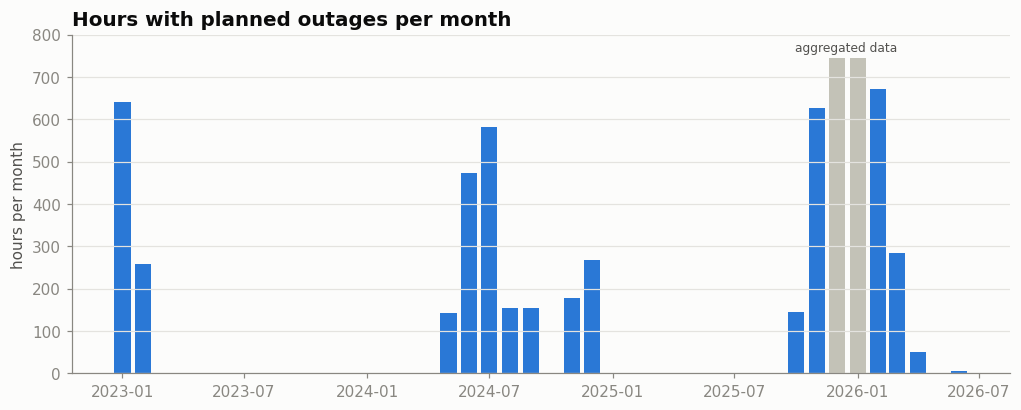

,outage_hours,agg
dt,,
2023-01,640,0
2023-02,258,0
2024-05,143,0
2024-06,472,0
2024-07,582,0
2024-08,155,0
2024-09,154,0
2024-11,177,0
2024-12,268,0


In [13]:
monthly = df.groupby(df["dt"].dt.to_period("M")).agg(
    outage_hours=("outage", "sum"), agg=("aggregated_period", "max"))
x = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4))
colors = np.where(monthly["agg"] == 1, "#c3c2b7", BLUE)
ax.bar(x, monthly["outage_hours"], width=24, color=colors)
ax.set_title("Hours with planned outages per month")
ax.set_ylabel("hours per month")
ax.grid(axis="x", visible=False)
ax.text(pd.Timestamp("2025-12-15"), 760, "aggregated data", ha="center", fontsize=8, color=INK2)
ax.set_ylim(0, 800)
save(fig, "01_monthly_outage_hours")
plt.show()

monthly[monthly["outage_hours"] > 0]

Outages came in four episodes: January–February 2023, which is the end of the winter 2022/23 wave that began before the data start; May–September 2024; November–December 2024; and October 2025–April 2026. The episode of summer 2024 shows that outages are not only a winter phenomenon.

An important feature of the data: in the most severe periods outages are marked in all 24 hours of the day. The longest such period lasted 113 days, from 09.11.2025 to 01.03.2026, and fully covers the aggregated period. In a crisis the binary feature "outages in this hour" therefore saturates, and the number of queues would be a better measure of intensity. However, queue information is missing exactly in the most severe periods: winter 2023, May and June 2024, and from mid-December 2025 to April 2026. Queues can therefore be used only as an auxiliary feature.

### 6.2. Daily profile

Share of outage hours for each hour of the day, for all days and separately for days with partial outages, when outages were applied in some hours but not in all 24. Here and below the aggregated period is excluded.

Days with outages: 264 | round-the-clock: 143 | partial: 121
Share of outage hours that fall on round-the-clock days: 69.8%


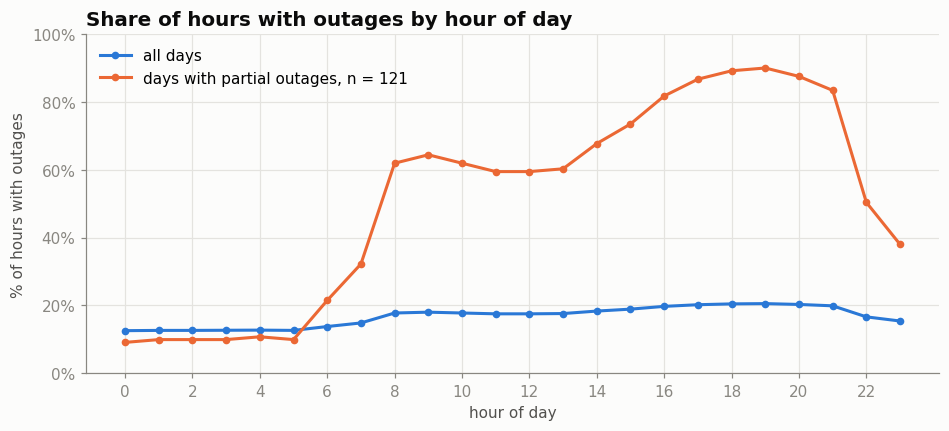

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
all days,12.6,12.6,12.6,12.7,12.7,12.6,13.8,14.8,17.8,18.0,...,18.3,18.9,19.7,20.2,20.5,20.5,20.3,19.9,16.6,15.4
partial days,9.1,9.9,9.9,9.9,10.7,9.9,21.5,32.2,62.0,64.5,...,67.8,73.6,81.8,86.8,89.3,90.1,87.6,83.5,50.4,38.0


In [14]:
by_hour = dfh.groupby(["season", "hour"])["outage"].mean().unstack(0) * 100
overall = dfh.groupby("hour")["outage"].mean() * 100

# Days by type: no outages, partial outages, round-the-clock outages
per_day = dfh.groupby("date")["outage"].agg(["sum", "size"])
full_days = per_day.index[per_day["sum"] == per_day["size"]]
partial_days = per_day.index[(per_day["sum"] > 0) & (per_day["sum"] < per_day["size"])]
partial = dfh[dfh["date"].isin(partial_days)].groupby("hour")["outage"].mean() * 100
print("Days with outages:", (per_day["sum"] > 0).sum(),
      "| round-the-clock:", len(full_days), "| partial:", len(partial_days))
print("Share of outage hours that fall on round-the-clock days: {:.1%}".format(
    per_day.loc[full_days, "sum"].sum() / per_day["sum"].sum()))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(overall.index, overall.values, color=BLUE, lw=2, marker="o", ms=4, label="all days")
ax.plot(partial.index, partial.values, color=ORANGE, lw=2, marker="o", ms=4,
        label=f"days with partial outages, n = {len(partial_days)}")
ax.set_title("Share of hours with outages by hour of day")
ax.set_xlabel("hour of day")
ax.set_ylabel("% of hours with outages")
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="upper left")
save(fig, "02_outages_by_hour")
plt.show()

pd.DataFrame({"all days": overall, "partial days": partial}).round(1).T

Of the 264 days with outages, 143 were round-the-clock days, and they contain 70% of all outage hours. On such days the hour of day carries no information, which is why the profile for all days looks flat: 12.6% at night against about 20% in the evening. The real daily pattern is visible on the 121 days with partial outages: about 10% of hours at night and 82–90% from 16:00 to 21:00.

This matters for the modelling in notebook 2: most of the variation in the hourly target is variation between days and seasons, not between hours of one day.

### 6.3. Heatmap: hour of day × month

Shows how the daily profile of outages changed over time. A darker colour means a larger share of days in the month when outages were applied in that hour. Solid dark columns correspond to periods of round-the-clock outages.

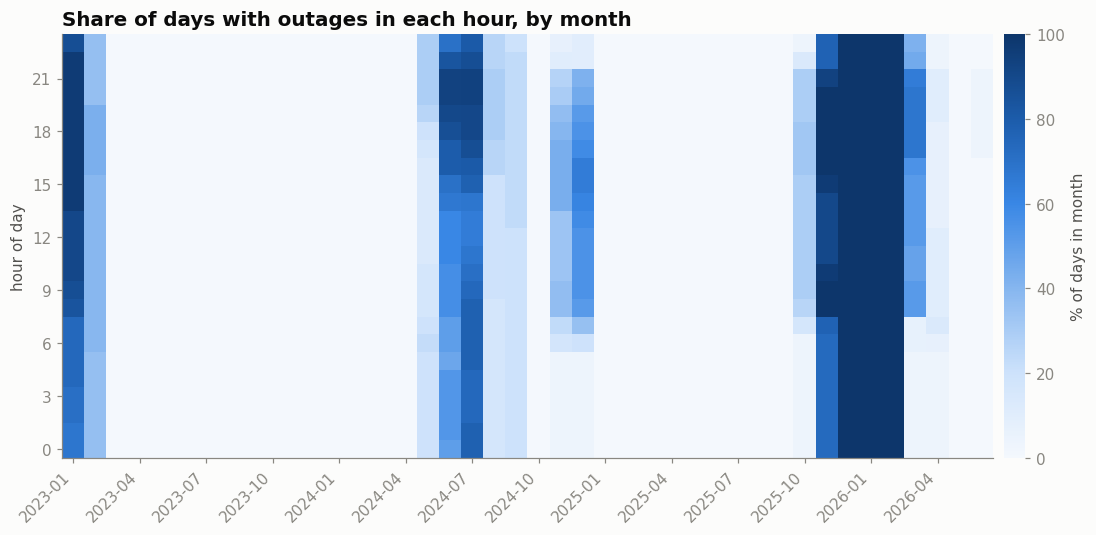

In [15]:
heat = (dfh.assign(ym=dfh["dt"].dt.to_period("M").astype(str))
        .pivot_table(index="hour", columns="ym", values="outage", aggfunc="mean") * 100)

fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(heat.values, aspect="auto", cmap=SEQ, vmin=0, vmax=100, origin="lower")
ax.set_xticks(range(0, heat.shape[1], 3))
ax.set_xticklabels(heat.columns[::3], rotation=45, ha="right")
ax.set_yticks(range(0, 24, 3))
ax.set_ylabel("hour of day")
ax.set_title("Share of days with outages in each hour, by month")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("% of days in month")
cb.outline.set_visible(False)
save(fig, "03_heatmap_hour_month")
plt.show()

### 6.4. Weather and outages

**Hypothesis 1.** The colder it is, the more frequent the outages, because consumption for heating grows.

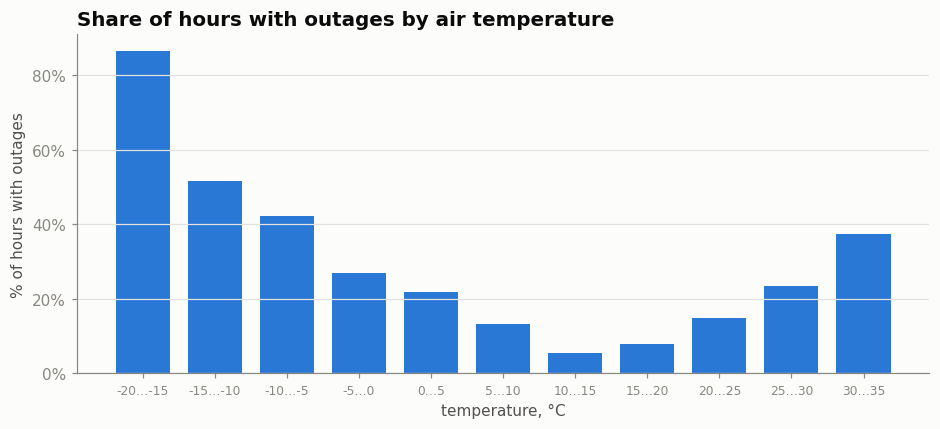

,mean,size
t_bin,,
"(-20, -15]",86.7,75
"(-15, -10]",51.5,235
"(-10, -5]",42.3,956
"(-5, 0]",27.0,3046
"(0, 5]",21.9,5187
"(5, 10]",13.3,4896
"(10, 15]",5.5,4315
"(15, 20]",7.7,4782
"(20, 25]",14.8,3998


In [16]:
bins = list(range(-25, 41, 5))
t = (dfh.assign(t_bin=pd.cut(dfh["temp_c"], bins))
     .groupby("t_bin", observed=True)["outage"].agg(["mean", "size"]))
t = t[t["size"] >= 50]            # drop intervals with few hours

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(t)), t["mean"] * 100, color=BLUE, width=0.75)
ax.set_xticks(range(len(t)))
ax.set_xticklabels([f"{int(i.left)}…{int(i.right)}" for i in t.index], rotation=0, fontsize=8)
ax.set_title("Share of hours with outages by air temperature")
ax.set_xlabel("temperature, °C")
ax.set_ylabel("% of hours with outages")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
save(fig, "04_outages_by_temperature")
plt.show()
t.assign(mean=lambda d: (d["mean"] * 100).round(1))

The relationship is U-shaped: there are more outages both in frost and in heat. Cold increases the load because of heating, heat because of air conditioning and lower generation efficiency. This is an important result, because a simple linear correlation with temperature would not reveal it.

**Hypothesis 2.** On sunny days there are fewer daytime outages because solar power plants are working. To separate the effect of the sun from the effect of the time of day, only daytime hours from 10:00 to 16:00 in the warm season, April to September, are compared.

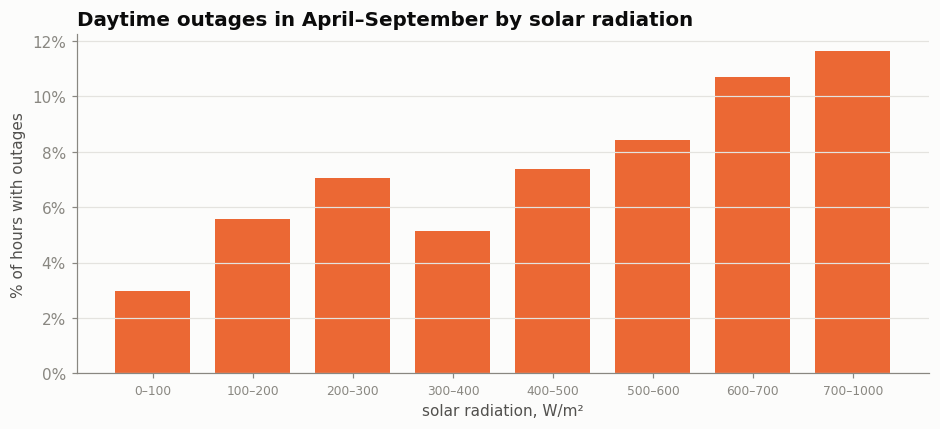

Share of daytime outage hours in April–September by year:
year
2023     0.0
2024    31.0
2025     0.0
2026     2.7
Correlation of daytime radiation and temperature: 0.52


,mean,size
r_bin,,
"(-0.001, 100.0]",3.0,67
"(100.0, 200.0]",5.6,179
"(200.0, 300.0]",7.1,170
"(300.0, 400.0]",5.1,292
"(400.0, 500.0]",7.4,433
"(500.0, 600.0]",8.4,689
"(600.0, 700.0]",10.7,878
"(700.0, 1000.0]",11.7,1132


In [17]:
day = dfh[dfh["hour"].between(10, 15) & dfh["month"].between(4, 9)]
rbins = [0, 100, 200, 300, 400, 500, 600, 700, 1000]
r = (day.assign(r_bin=pd.cut(day["radiation_wm2"], rbins, include_lowest=True))
     .groupby("r_bin", observed=True)["outage"].agg(["mean", "size"]))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(r)), r["mean"] * 100, color=ORANGE, width=0.75)
ax.set_xticks(range(len(r)))
ax.set_xticklabels([f"{int(i.left)}–{int(i.right)}" for i in r.index], fontsize=8)
ax.set_title("Daytime outages in April–September by solar radiation")
ax.set_xlabel("solar radiation, W/m²")
ax.set_ylabel("% of hours with outages")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
save(fig, "05_daytime_outages_by_radiation")
plt.show()
print("Share of daytime outage hours in April–September by year:")
print((day.groupby("year")["outage"].mean() * 100).round(1).to_string())
print("Correlation of daytime radiation and temperature:", round(day["radiation_wm2"].corr(day["temp_c"]), 2))
r.assign(mean=lambda d: (d["mean"] * 100).round(1))

The result is the opposite of the hypothesis: with stronger sun there are more daytime outages. The reason is confounding. Almost all daytime outages of the warm season fall in summer 2024, when the power system was weakened and sunny days were also hot. Solar radiation is correlated with temperature, so this simple chart shows the effect of heat and of a particular year rather than the effect of the sun. The contribution of solar generation can only be tested with a model that accounts for temperature and period at the same time.

### 6.5. Massive attacks and outages

**Hypothesis 3.** Outages are applied after massive attacks on energy infrastructure, and the effect lasts for some time while the power system recovers.

First, the overall picture: the upper chart shows every massive attack and the number of missiles and drones fired, the lower chart shows outage hours per week. The charts share the time axis but have separate scales.

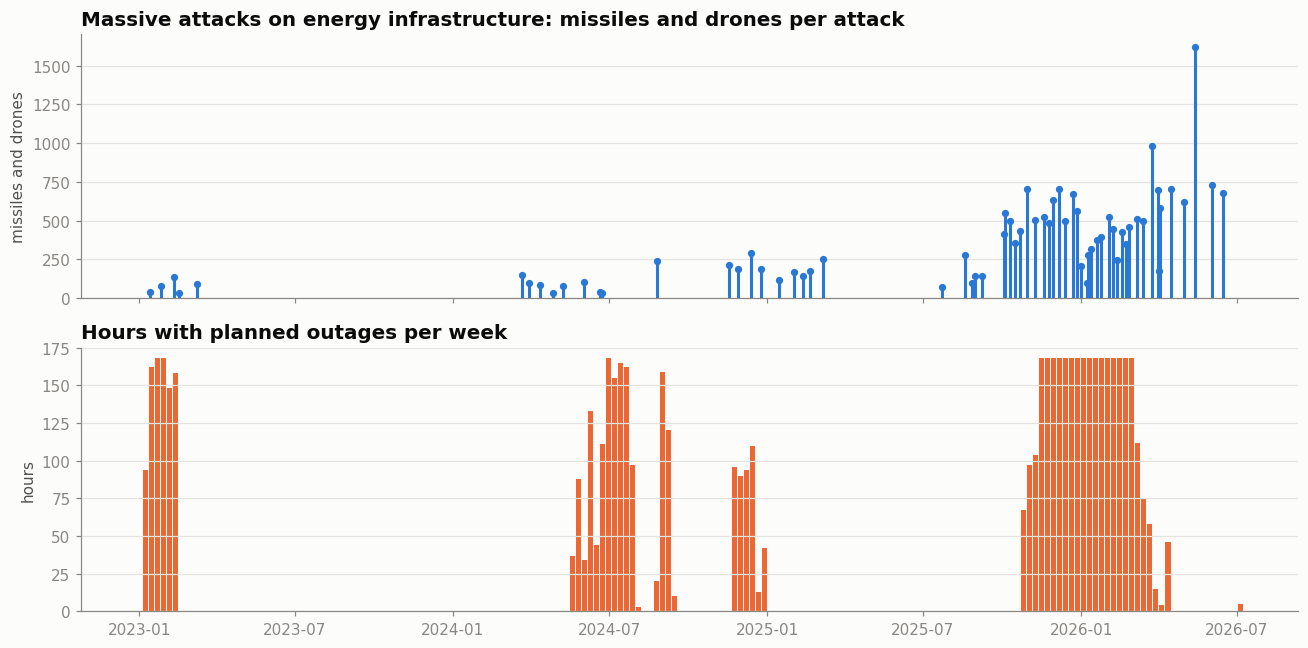

In [18]:
att = attacks[attacks.index >= START]
weekly = df.set_index("dt")["outage"].resample("W").sum()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
a1.vlines(att.index, 0, att["fired"], color=BLUE, lw=2)
a1.scatter(att.index, att["fired"], color=BLUE, s=14, zorder=3)
a1.set_title("Massive attacks on energy infrastructure: missiles and drones per attack")
a1.set_ylabel("missiles and drones")
a1.set_ylim(0)
a1.grid(axis="x", visible=False)
a2.bar(weekly.index, weekly.values, width=6, color=ORANGE)
a2.set_title("Hours with planned outages per week")
a2.set_ylabel("hours")
a2.set_ylim(0, 175)
a2.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "08_attacks_and_outages_timeline")
plt.show()

Now the test of the hypothesis: the share of outage hours by days since the last massive attack and by the number of attacks in the previous 30 days.

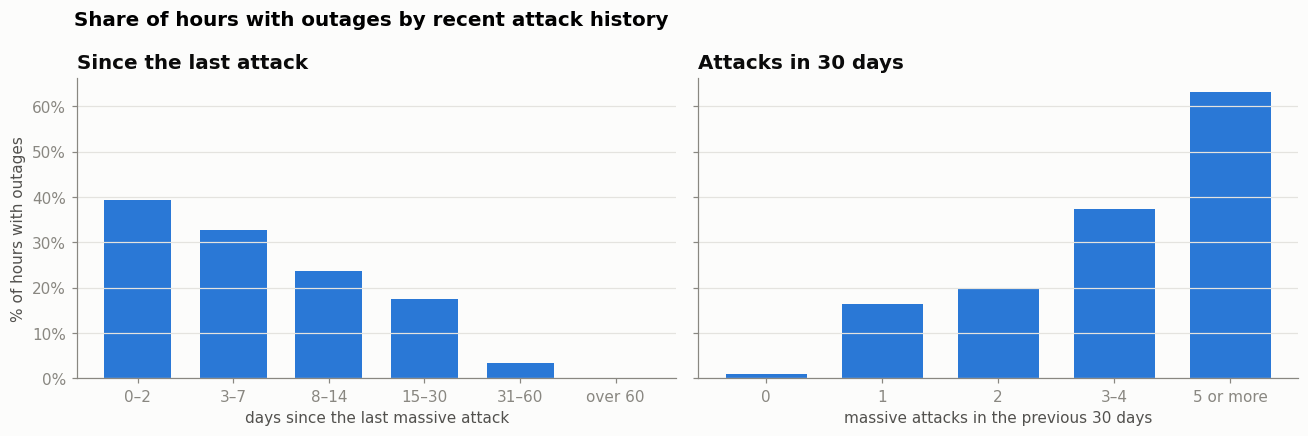

,mean,size
b,,
0–2,39.3,3935
3–7,32.7,5399
8–14,23.6,4272
15–30,17.6,2854
31–60,3.3,2880
over 60,0.0,10104


,mean,size
b,,
0,0.9,13080
1,16.3,3694
2,19.7,5951
3–4,37.4,4727
5 or more,63.2,1992


In [19]:
lag_bins = [-1, 2, 7, 14, 30, 60, 10_000]
lag_labels = ["0–2", "3–7", "8–14", "15–30", "31–60", "over 60"]
lag = (dfh.assign(b=pd.cut(dfh["days_since_attack"], lag_bins, labels=lag_labels))
       .groupby("b", observed=True)["outage"].agg(["mean", "size"]))

cnt_bins = [-1, 0, 1, 2, 4, 100]
cnt_labels = ["0", "1", "2", "3–4", "5 or more"]
cnt = (dfh.assign(b=pd.cut(dfh["attacks_30d"], cnt_bins, labels=cnt_labels))
       .groupby("b", observed=True)["outage"].agg(["mean", "size"]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
a1.bar(range(len(lag)), lag["mean"] * 100, color=BLUE, width=0.7)
a1.set_xticks(range(len(lag)))
a1.set_xticklabels(lag.index)
a1.set_title("Since the last attack")
a1.set_xlabel("days since the last massive attack")
a1.set_ylabel("% of hours with outages")
a2.bar(range(len(cnt)), cnt["mean"] * 100, color=BLUE, width=0.7)
a2.set_xticks(range(len(cnt)))
a2.set_xticklabels(cnt.index)
a2.set_title("Attacks in 30 days")
a2.set_xlabel("massive attacks in the previous 30 days")
for a in (a1, a2):
    a.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    a.grid(axis="x", visible=False)
fig.suptitle("Share of hours with outages by recent attack history", x=0.06, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "09_outages_by_attack_history")
plt.show()

display(lag.assign(mean=lambda d: (d["mean"] * 100).round(1)))
display(cnt.assign(mean=lambda d: (d["mean"] * 100).round(1)))

In [20]:
late = dfh[(dfh["attacks_30d"] == 0) & (dfh["outage"] == 1)]
print("Outage hours without an attack in the previous 30 days:", len(late))
late.groupby("date").agg(outage_hours=("outage", "sum"), days_since_attack=("days_since_attack", "first"))

Outage hours without an attack in the previous 30 days: 120


,outage_hours,days_since_attack
date,,
2024-07-22,24,30
2024-07-23,24,31
2024-07-24,17,32
2024-07-25,5,33
2024-07-26,17,34
2024-07-27,6,35
2024-07-28,4,36
2024-07-29,3,37
2024-08-19,4,58


The hypothesis is supported, and the association is strong. In the first two days after a massive attack outages were applied in 39% of hours, after 15–30 days in 18%, after 31–60 days in only 3%, and when more than 60 days had passed there were no planned outages at all. Accumulation works the same way: with no attacks in the previous 30 days outages occurred in less than 1% of hours, and with five or more attacks in 63%.

The table above lists all 120 outage hours without an attack in the previous 30 days. All of them belong to late July and August 2024, 30 to 60 days after the last attack of that spring and summer series. In this sample outages never occurred later than 60 days after a massive attack. The 30-day window itself is a convention and not a measured recovery time: these charts cannot separate the recovery of the power system from the change of season that usually follows a series of attacks.

### 6.6. Frost or attacks?

Cold weather and attacks coincide in time, because the strongest attacks happen in winter. To separate the two factors, hours are grouped by temperature and by the presence of attacks in the previous 30 days at the same time.

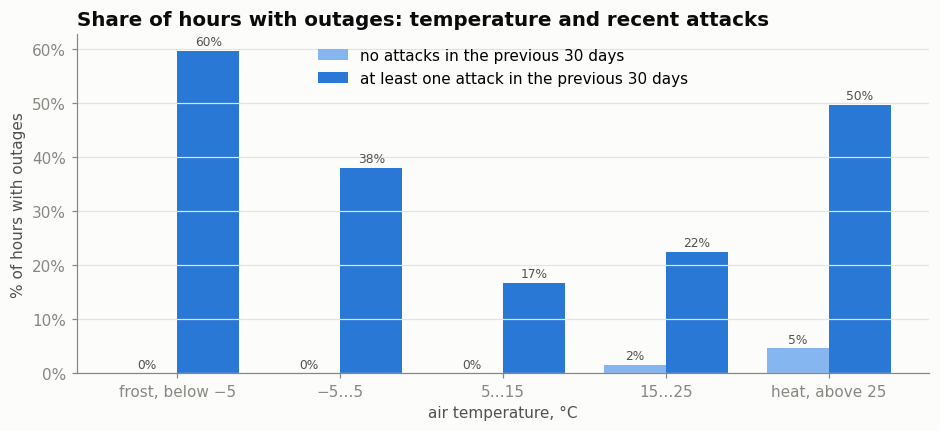

a,attacks in 30 days,no attacks
t,,
"frost, below −5",59.7,0.0
−5…5,38.0,0.0
5…15,16.7,0.0
15…25,22.4,1.5
"heat, above 25",49.7,4.6


a,attacks in 30 days,no attacks
t,,
"frost, below −5",1024,263
−5…5,5158,3075
5…15,5316,3895
15…25,3957,4823
"heat, above 25",909,1024


In [21]:
t_groups = pd.cut(dfh["temp_c"], [-40, -5, 5, 15, 25, 50],
                  labels=["frost, below −5", "−5…5", "5…15", "15…25", "heat, above 25"])
a_groups = np.where(dfh["attacks_30d"] > 0, "attacks in 30 days", "no attacks")
cross = (dfh.assign(t=t_groups, a=a_groups)
         .pivot_table(index="t", columns="a", values="outage", aggfunc=["mean", "size"], observed=True))
share = (cross["mean"] * 100).round(1)
hours = cross["size"]

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.38
xs = np.arange(len(share))
ax.bar(xs - w / 2, share["no attacks"], w, color="#86b6ef", label="no attacks in the previous 30 days")
ax.bar(xs + w / 2, share["attacks in 30 days"], w, color=BLUE, label="at least one attack in the previous 30 days")
ax.set_xticks(xs)
ax.set_xticklabels(share.index)
ax.set_title("Share of hours with outages: temperature and recent attacks")
ax.set_xlabel("air temperature, °C")
ax.set_ylabel("% of hours with outages")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
for off, col in [(-w / 2, "no attacks"), (w / 2, "attacks in 30 days")]:
    for xi, v in zip(xs, share[col]):
        ax.text(xi + off, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=INK2)
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
save(fig, "10_temperature_vs_attacks")
plt.show()

display(share)
display(hours)

Without attacks in the previous 30 days there were almost no outages at any temperature: the share was zero below 15 °C and did not exceed 5% even in heat above 25 °C. When attacks had occurred, the share of outage hours followed temperature: 60% in frost below −5 °C, 50% in heat above 25 °C and 17% in mild weather from 5 to 15 °C.

Weather alone, without a damaged power system, did not lead to planned outages. The shares after attacks, however, are averages over very different seasons. The next two tables take only days with attacks in the previous 30 days and compare the same weather in different quarters: first cold days with a mean temperature below 0 °C, then hot days above 22 °C.

In [22]:
day = dfh.groupby("date").agg(share=("outage", "mean"), temp=("temp_c", "mean"),
                              attacks_30d=("attacks_30d", "first"))
day["quarter"] = pd.PeriodIndex(pd.to_datetime(day.index), freq="Q")
att_days = day[day["attacks_30d"] > 0]

def by_quarter(d):
    return d.groupby("quarter").agg(days=("share", "size"),
                                    outage_hours_pct=("share", lambda s: s.mean() * 100),
                                    mean_temp_c=("temp", "mean")).round(1)

# Cold days after attacks
by_quarter(att_days[att_days["temp"] < 0])

,days,outage_hours_pct,mean_temp_c
quarter,,,
2023Q1,39,67.4,-2.6
2024Q4,19,52.2,-2.0
2025Q1,33,0.0,-4.5
2026Q1,25,100.0,-8.2


In [23]:
# Hot days after attacks
by_quarter(att_days[att_days["temp"] > 22])

,days,outage_hours_pct,mean_temp_c
quarter,,,
2024Q2,6,87.5,23.5
2024Q3,30,90.8,25.1
2025Q3,15,0.0,23.6
2026Q2,15,1.4,24.1


The same weather after attacks gave opposite results in different seasons. On cold days outages covered 67% of hours in Q1 2023, 52% in Q4 2024 and 100% in Q1 2026, but 0% in Q1 2025, although those 33 days were colder on average, −4.5 °C, than the cold days of 2023 and 2024. On hot days the share was about 90% in summer 2024 and 0–1% in Q3 2025 and Q2 2026.

Weather therefore amplifies outages in seasons when the power system is short of capacity, but it does not decide whether attacks turn into outages. That depends on the state of the system after each series of attacks, and this state is not in the data.

Back to solar radiation. Taking attacks into account shows whether daytime outages in the warm season were related to the sun or to the fact that the power system was damaged.

In [24]:
day2 = dfh[dfh["hour"].between(10, 15) & dfh["month"].between(4, 9)]
(day2.assign(r=pd.cut(day2["radiation_wm2"], [0, 300, 600, 1000], include_lowest=True,
                      labels=["weak", "medium", "strong"]),
             a=np.where(day2["attacks_30d"] > 0, "attacks", "no attacks"))
 .pivot_table(index="r", columns="a", values="outage", aggfunc="mean", observed=True) * 100).round(1)

a,attacks,no attacks
r,,
weak,11.2,0.0
medium,14.6,0.4
strong,21.6,1.5


Without attacks there were practically no daytime outages in the warm season at any level of sunshine. After attacks, there are still more outages with strong sun than with weak sun. Most likely heat is still at work here, because the sunniest days are also the hottest. The separate contribution of solar plants cannot be seen from this grouping; it will be estimated by a model that accounts for all factors at once.

### 6.7. Day of week

In [25]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
d = dfh.groupby("dow")["outage"].mean() * 100
pd.DataFrame({"day": dow_names, "% of hours with outages": d.round(1).values})

,day,% of hours with outages
0,Mon,16.3
1,Tue,16.9
2,Wed,17.2
3,Thu,18.4
4,Fri,19.1
5,Sat,15.8
6,Sun,13.3


### 6.8. Context: electricity import

Net import shows how much the power system depends on neighbouring countries. The two charts share the time axis but have separate scales, so that different units are not mixed.

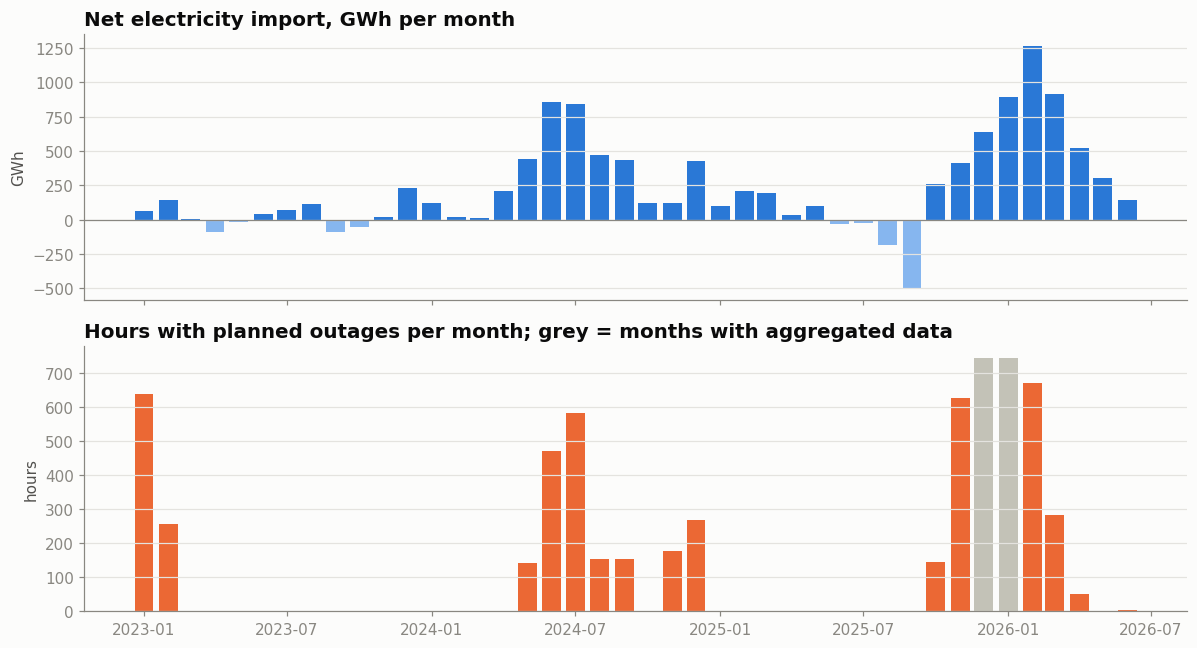

Correlation of monthly net import and outage hours: 0.73


In [26]:
m = df.groupby(df["dt"].dt.to_period("M")).agg(
    net_import_gwh=("net_import_mwh", lambda s: s.sum() / 1000),
    outage_hours=("outage", "sum"))
x = m.index.to_timestamp()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
a1.bar(x, m["net_import_gwh"], width=24,
       color=np.where(m["net_import_gwh"] >= 0, BLUE, "#86b6ef"))
a1.axhline(0, color=MUTED, lw=0.8)
a1.set_title("Net electricity import, GWh per month")
a1.set_ylabel("GWh")
a1.grid(axis="x", visible=False)
agg_m = df.groupby(df["dt"].dt.to_period("M"))["aggregated_period"].max()
a2.bar(x, m["outage_hours"], width=24, color=np.where(agg_m.values == 1, "#c3c2b7", ORANGE))
a2.set_title("Hours with planned outages per month; grey = months with aggregated data")
a2.set_ylabel("hours")
a2.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "06_net_import_vs_outages")
plt.show()

print("Correlation of monthly net import and outage hours:",
      round(m["net_import_gwh"].corr(m["outage_hours"]), 2))

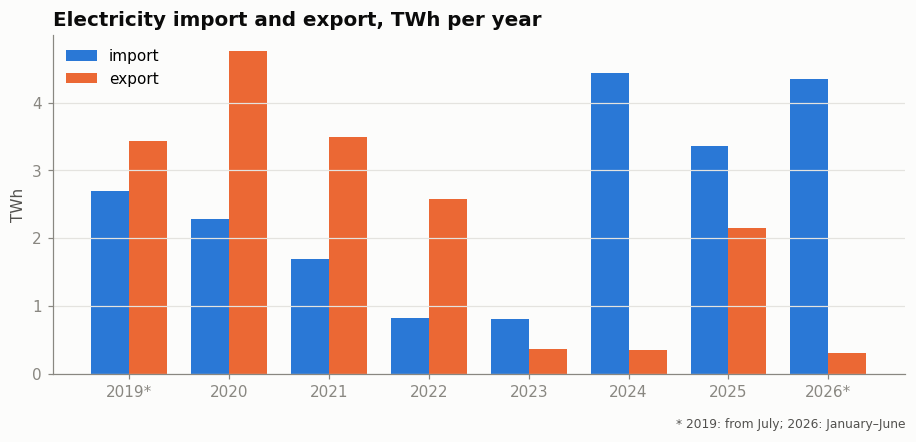

regime,import_mwh,export_mwh
year,,
2019,2.70,3.43
2020,2.29,4.76
2021,1.69,3.49
2022,0.82,2.57
2023,0.81,0.37
2024,4.44,0.35
2025,3.35,2.14
2026,4.35,0.31


In [27]:
# Long-term context since 2019
yearly = (trade.assign(year=trade["dt"].dt.year)
          .groupby("year")[["import_mwh", "export_mwh"]].sum() / 1e6)

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.38
ax.bar(yearly.index - w / 2, yearly["import_mwh"], w, color=BLUE, label="import")
ax.bar(yearly.index + w / 2, yearly["export_mwh"], w, color=ORANGE, label="export")
ax.set_title("Electricity import and export, TWh per year")
ax.set_ylabel("TWh")
ax.set_xticks(yearly.index)
ax.set_xticklabels([str(y) if y not in (2019, 2026) else f"{y}*" for y in yearly.index])
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
ax.text(1, -0.16, "* 2019: from July; 2026: January–June", transform=ax.transAxes,
        ha="right", fontsize=8, color=INK2)
save(fig, "07_yearly_import_export")
plt.show()
yearly.round(2)

### 6.9. Correlations of numeric features

In [28]:
# queues_max is excluded: it is non-zero only when there are outages
cols = ["outage", "temp_c", "cloud_pct", "radiation_wm2", "wind_kmh",
        "net_import_mwh", "hour", "is_weekend", "attack_day", "days_since_attack",
        "attacks_7d", "attacks_30d", "fired_30d", "not_down_30d"]
dfh[cols].corr()["outage"].drop("outage").sort_values().round(3)

days_since_attack   -0.294
temp_c              -0.147
radiation_wm2       -0.060
wind_kmh            -0.044
is_weekend          -0.037
hour                 0.061
cloud_pct            0.081
attack_day           0.117
fired_30d            0.299
not_down_30d         0.306
attacks_7d           0.322
net_import_mwh       0.468
attacks_30d          0.486
Name: outage, dtype: float64

## 7. Preliminary conclusions

The conclusions below were written after running the notebook and are refined by the statistical tests and models in the next notebook.

1. Outages came in four episodes: January–February 2023, May–September 2024, November–December 2024 and October 2025–April 2026. In the most severe periods they were applied around the clock, for up to 113 days in a row in winter 2025/26. Round-the-clock days contain 70% of all outage hours.
2. **Massive attacks on energy infrastructure are a precondition for outages.** Without attacks in the previous 30 days there were almost no planned outages in any weather, and none later than 60 days after an attack. In the first two days after an attack outages were applied in 39% of hours. With five or more attacks per month the share rose to 63%.
3. **Attacks do not always lead to outages, and weather explains this only partly.** After attacks, outages were applied in 60% of hours in frost below −5 °C, 50% in heat above 25 °C and 17% in mild weather. These are averages over very different seasons: in Q1 2025 frost after attacks caused no outages at all, while in Q1 2026 it meant outages in every hour.
4. On days with partial outages the probability of an outage is about 10% at night and 82–90% in the evening peak from 16:00 to 21:00.
5. The overall relationship with temperature is U-shaped: at −20…−15 °C outages were applied in 87% of hours, at 10…15 °C in 5.5%, at 30…35 °C in 37%.
6. The analysis did not confirm that sunny weather reduces daytime outages. The effect of the sun is confounded with the effect of heat, so it has to be tested with a model.
7. There are more outages on weekdays than on weekends: 19% of hours on Fridays, 13% on Sundays.
8. Months with outages coincide with months of high net import; the correlation of monthly values is 0.73.

**Data limitations:** the dataset contains only large-scale outages, not local ones; the strike dataset contains only massive attacks, not daily local strikes, and gives no time of day for an attack; the number of hits is estimated as fired minus shot down; there are no data for autumn 2022 or after June 2026; weather in Kyiv is used as a proxy for the whole country; the period from 10.12.2025 to 28.01.2026 is excluded from hourly analysis.

**Next notebook:** statistical hypothesis tests and a model that estimates the probability of an outage in a given hour.